In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

!pip install pandas fiona shapely pyproj rtree 
!pip install contextily
!pip install geopandas
!pip install topojson
!pip install py7zr geopandas openpyxl tqdm s3fs ipywidgets --quiet
!pip install PyYAML --quiet
!pip install cartiflette --quiet
!pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 91.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [fiona]32m3/4 [fiona]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 97.4 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [contextily]7 [rasterio]


Remarque : il s'agit des données parcoursup de 2025 ici. Il est aussi possbile d'avoir ces données sur les années précédentes.

In [1]:
parcoursup = pd.read_csv("../fr-esr-parcoursup.csv", sep=";",encoding="utf-8-sig")



parcoursup = parcoursup[[
    'Code départemental de l’établissement',
    'Département de l’établissement',
    'Académie de l’établissement',
    'Sélectivité',
    'Taux d’accès',
    '% d’admis néo bacheliers issus de la même académie',
    'Dont effectif des admis issus de la même académie',
    '% d’admis néo bacheliers avec mention Assez Bien au bac',
    '% d’admis néo bacheliers avec mention Bien au bac',
    '% d’admis néo bacheliers avec mention Très Bien au bac',
    '% d’admis néo bacheliers avec mention Très Bien avec félicitations au bac',
    'Dont % d’admis avec mention (BG)',
    'Dont % d’admis avec mention (BT)',
    'Dont % d’admis avec mention (BP)',
    'Effectif des admis néo bacheliers',
    'Dont effectif des admis néo bacheliers avec mention Assez Bien au bac',
    'Dont effectif des admis néo bacheliers avec mention Bien au bac',
    'Dont effectif des admis néo bacheliers avec mention Très Bien au bac',
    'Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac'
]]

parcoursup.columns = parcoursup.columns.str.replace("’", "'") #problème sinon pour appeler les colonnes

NameError: name 'pd' is not defined

In [3]:
parcoursup.head()

,Code départemental de l'établissement,Département de l'établissement,Académie de l'établissement,Sélectivité,Taux d'accès,% d'admis néo bacheliers issus de la même académie,Dont effectif des admis issus de la même académie,% d'admis néo bacheliers avec mention Assez Bien au bac,% d'admis néo bacheliers avec mention Bien au bac,% d'admis néo bacheliers avec mention Très Bien au bac,% d'admis néo bacheliers avec mention Très Bien avec félicitations au bac,Dont % d'admis avec mention (BG),Dont % d'admis avec mention (BT),Dont % d'admis avec mention (BP),Effectif des admis néo bacheliers,Dont effectif des admis néo bacheliers avec mention Assez Bien au bac,Dont effectif des admis néo bacheliers avec mention Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac
0,12,Aveyron,Toulouse,formation non sélective,7.0,90.0,18,10.0,65.0,15.0,5.0,90.0,5.0,0.0,20,2,13,3,1
1,75,Paris,Paris,formation non sélective,100.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0
2,95,Val-d'oise,Versailles,formation sélective,77.0,69.0,20,17.0,21.0,0.0,0.0,24.0,7.0,7.0,29,5,6,0,0
3,92,Hauts-de-Seine,Versailles,formation sélective,12.0,60.0,48,34.0,59.0,2.0,0.0,44.0,51.0,0.0,80,27,47,2,0
4,69,Rhône,Lyon,formation sélective,60.0,35.0,8,43.0,43.0,9.0,0.0,96.0,0.0,0.0,23,10,10,2,0


In [4]:
parcoursup.columns

Index(['Code départemental de l'établissement',
       'Département de l'établissement', 'Académie de l'établissement',
       'Sélectivité', 'Taux d'accès',
       '% d'admis néo bacheliers issus de la même académie',
       'Dont effectif des admis issus de la même académie',
       '% d'admis néo bacheliers avec mention Assez Bien au bac',
       '% d'admis néo bacheliers avec mention Bien au bac',
       '% d'admis néo bacheliers avec mention Très Bien au bac',
       '% d'admis néo bacheliers avec mention Très Bien avec félicitations au bac',
       'Dont % d'admis avec mention (BG)', 'Dont % d'admis avec mention (BT)',
       'Dont % d'admis avec mention (BP)', 'Effectif des admis néo bacheliers',
       'Dont effectif des admis néo bacheliers avec mention Assez Bien au bac',
       'Dont effectif des admis néo bacheliers avec mention Bien au bac',
       'Dont effectif des admis néo bacheliers avec mention Très Bien au bac',
       'Dont effectif des admis néo bacheliers avec me

In [5]:
parcoursup_dept = parcoursup.groupby(["Code départemental de l'établissement", "Département de l'établissement"]).agg({
    "Effectif des admis néo bacheliers": "sum",
    "Dont effectif des admis néo bacheliers avec mention Assez Bien au bac": "sum",
    "Dont effectif des admis néo bacheliers avec mention Bien au bac": "sum",
    "Dont effectif des admis néo bacheliers avec mention Très Bien au bac": "sum",
    "Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac": "sum"
}).reset_index() #j'ai du demander à l'ia pour avoir un index sur une seule ligne et elle m'a proposé cette solution (je précise par transparence). Sans cela l'index était sur deux lignes

parcoursup_dept.head()

,Code départemental de l'établissement,Département de l'établissement,Effectif des admis néo bacheliers,Dont effectif des admis néo bacheliers avec mention Assez Bien au bac,Dont effectif des admis néo bacheliers avec mention Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac
0,01,Ain,1300,537,280,57,3
1,02,Aisne,1780,591,289,69,3
2,03,Allier,1327,508,237,33,1
3,04,Alpes-de-Haute-Provence,243,87,49,9,1
4,05,Hautes-Alpes,308,124,53,17,0


# Mention des bacheliers par département

In [6]:
parcoursup_dept["Taux réel Assez Bien (%)"] = (parcoursup_dept["Dont effectif des admis néo bacheliers avec mention Assez Bien au bac"] / parcoursup_dept["Effectif des admis néo bacheliers"]) * 100
parcoursup_dept["Taux réel Bien (%)"] = (parcoursup_dept["Dont effectif des admis néo bacheliers avec mention Bien au bac"] / parcoursup_dept["Effectif des admis néo bacheliers"]) * 100
parcoursup_dept["Taux réel Très Bien (%)"] = (parcoursup_dept["Dont effectif des admis néo bacheliers avec mention Très Bien au bac"] / parcoursup_dept["Effectif des admis néo bacheliers"]) * 100
parcoursup_dept["Taux réel Félicitations (%)"] = (parcoursup_dept["Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac"] / parcoursup_dept["Effectif des admis néo bacheliers"]) * 100

parcoursup_dept.head()

,Code départemental de l'établissement,Département de l'établissement,Effectif des admis néo bacheliers,Dont effectif des admis néo bacheliers avec mention Assez Bien au bac,Dont effectif des admis néo bacheliers avec mention Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac,Taux réel Assez Bien (%),Taux réel Bien (%),Taux réel Très Bien (%),Taux réel Félicitations (%)
0,01,Ain,1300,537,280,57,3,41.307692,21.538462,4.384615,0.230769
1,02,Aisne,1780,591,289,69,3,33.202247,16.235955,3.876404,0.168539
2,03,Allier,1327,508,237,33,1,38.281839,17.859834,2.486812,0.075358
3,04,Alpes-de-Haute-Provence,243,87,49,9,1,35.802469,20.164609,3.703704,0.411523
4,05,Hautes-Alpes,308,124,53,17,0,40.259740,17.207792,5.519481,0.000000


## Résultat d'attractivité des départements (mesuré grace à la mobilité)

In [7]:
parcoursup_dept_att = parcoursup.groupby(["Code départemental de l'établissement", "Département de l'établissement"]).agg(admis=("Effectif des admis néo bacheliers", "sum"),
admis_meme_academie=("Dont effectif des admis issus de la même académie", "sum")).reset_index()

parcoursup_dept_att["admis_venus_d_ailleurs"] = (parcoursup_dept_att["admis"] - parcoursup_dept_att["admis_meme_academie"])
parcoursup_dept_att["attractivite (%)"] = (100 * parcoursup_dept_att["admis_venus_d_ailleurs"] / parcoursup_dept_att["admis"])
parcoursup_dept_att = parcoursup_dept_att.sort_values("attractivite (%)", ascending=False)
parcoursup_dept_att.head(15)

,Code départemental de l'établissement,Département de l'établissement,admis,admis_meme_academie,admis_venus_d_ailleurs,attractivite (%)
75,75,Paris,42787,9862,32925,76.950943
104,99,Etranger,387,143,244,63.049096
18,19,Corrèze,1098,513,585,53.278689
21,23,Creuse,256,124,132,51.562500
94,94,Val-de-Marne,11763,6177,5586,47.487886
65,65,Hautes-Pyrénées,1474,795,679,46.065129
92,92,Hauts-de-Seine,12398,6792,5606,45.216970
14,15,Cantal,399,222,177,44.360902
69,69,Rhône,24345,13585,10760,44.197987
93,93,Seine-Saint-Denis,9967,5650,4317,43.312933


On se doute que les résultats ci-dessus ne rendent pas forcément très fidèlement compte de l'attractivité réelle des régions en termes d'éducation. Cela est principalement dû à des effets de volumes. Ci-après le même calcul mais avec un seuil minimal d'étudiants admis dans le département pour éviter que les petits départements peu représentatifs "fausse" les résultats. (Ou du moins qu'ils en donnent une vision plus représentative).

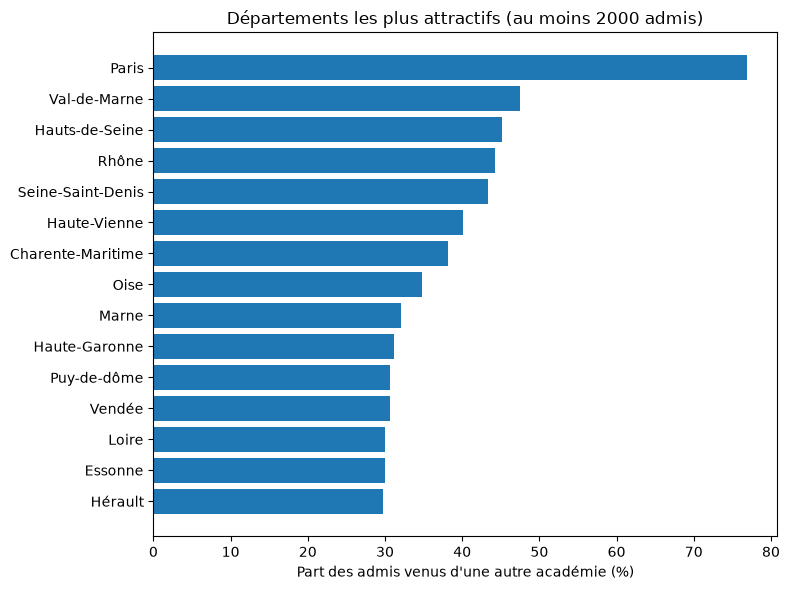

In [8]:
SEUIL = 2000 # donne les mêmes résultats avec 3000, 5000 et plus
fiables = parcoursup_dept_att[parcoursup_dept_att["admis"] >= SEUIL]
fiables = fiables.sort_values("attractivite (%)", ascending=False).head(15)

top15_fiables = fiables.sort_values("attractivite (%)")

plt.figure(figsize=(8, 6))
plt.barh(top15_fiables["Département de l'établissement"],top15_fiables["attractivite (%)"])
plt.xlabel("Part des admis venus d'une autre académie (%)")
plt.title(f"Départements les plus attractifs (au moins {SEUIL} admis)")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Taux de bacheliers Pro parmi les admis, par département métropolitain - Parcoursup 2025')

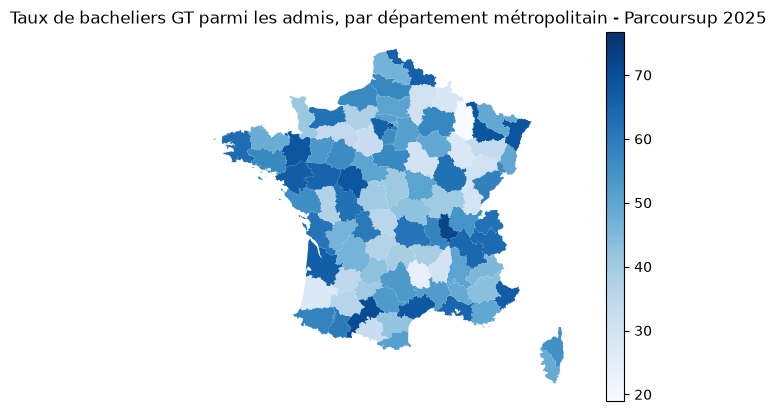

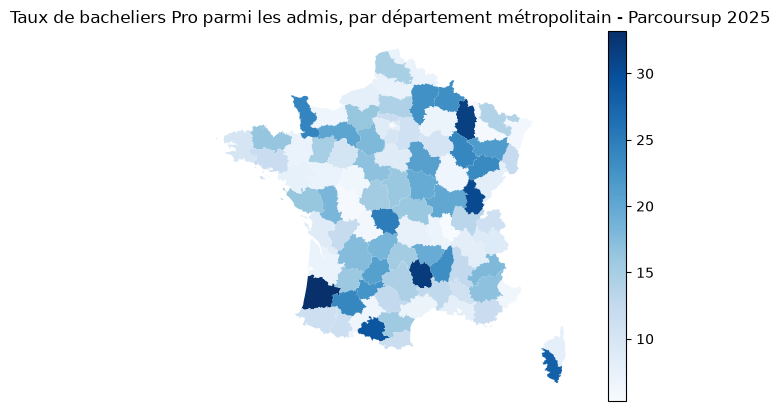

In [13]:
parcoursup["nb_bac_gt"] = parcoursup["Dont % d'admis avec mention (BG)"] / 100 * parcoursup["Effectif des admis néo bacheliers"]
parcoursup["nb_bac_bt"] = parcoursup["Dont % d'admis avec mention (BT)"] / 100 * parcoursup["Effectif des admis néo bacheliers"]
parcoursup["nb_bac_pro"] = parcoursup["Dont % d'admis avec mention (BP)"] / 100 * parcoursup["Effectif des admis néo bacheliers"]

dept_bac = parcoursup.groupby(["Code départemental de l'établissement", "Département de l'établissement"]).agg(
admis=("Effectif des admis néo bacheliers", "sum"),nb_bac_gt=("nb_bac_gt", "sum"),nb_bac_bt=("nb_bac_bt", "sum"),nb_bac_pro=("nb_bac_pro", "sum"),).reset_index()

dept_bac["Taux de bacheliers GT"] = 100 * (dept_bac["nb_bac_gt"] + dept_bac["nb_bac_bt"]) / dept_bac["admis"]
dept_bac["Taux de bacheliers Pro"] = 100 * dept_bac["nb_bac_pro"] / dept_bac["admis"]

#visualisation avec carte faite à l'aide de l'ia

from cartiflette import carti_download

france = carti_download(
    values=["France"],
    crs=4326,
    borders="DEPARTEMENT",
    vectorfile_format="geojson",
    simplification=50,
    filter_by="FRANCE_ENTIERE",
    source="EXPRESS-COG-CARTO-TERRITOIRE",
    year=2022,
)

france_metro = france[~france["INSEE_DEP"].isin(["971", "972", "973", "974", "976"])]
france_metro["INSEE_DEP"] = france_metro["INSEE_DEP"].astype(str).str.zfill(2)
dept_bac["Code départemental de l'établissement"] = dept_bac["Code départemental de l'établissement"].astype(str).str.zfill(2)

france_metro = france_metro.merge(
    dept_bac,
    left_on="INSEE_DEP",
    right_on="Code départemental de l'établissement",
    how="left",
)

graph_gt = france_metro.plot(
    column="Taux de bacheliers GT",
    legend=True,
    cmap="Blues",
)
graph_gt.set_axis_off()
graph_gt.set_title("Taux de bacheliers GT parmi les admis, par département métropolitain - Parcoursup 2025")

graph_pro = france_metro.plot(
    column="Taux de bacheliers Pro",
    legend=True,
    cmap="Blues",
)
graph_pro.set_axis_off()
graph_pro.set_title("Taux de bacheliers Pro parmi les admis, par département métropolitain - Parcoursup 2025")